# Replicating the DFTHC resource estimates of Low et al. (PRX 2025)

This notebook uses the `dfthc` package in this repository to reproduce the resource estimates of

> G. H. Low *et al.*, *Fast quantum simulation of electronic structure by spectrum amplification*,
> [PRX **15**, 041016 (2025)](https://journals.aps.org/prx/abstract/10.1103/pb2g-j9cw),
> [arXiv:2502.15882](https://arxiv.org/abs/2502.15882).

The paper builds a block encoding of the electronic-structure Hamiltonian from a double-factorized
tensor hypercontraction (DFTHC) and costs its qubitized walk gate by gate (its Table III, and App. B).
Here every block is a PennyLane operator that compiles, with `qp.qjit(capture=True)` and graph-based
`qp.decompose`, down to Cliffords, `TemporaryAND`, measured AND-uncomputes and mid-circuit
measurements. `qp.analyze` then counts the compiled program exactly. The Qualtran implementation
[dfthcbe](https://github.com/Covestro-HPQC/dfthcbe) is a second point of comparison.

What the notebook reproduces:

1. **Toffolis per walk step** for H$_2$, naphthalene, Fe$_2$S$_2$, Fe$_4$S$_4$ and FeMoco-54: compiled
   and counted, checked against the closed forms in `dfthc.costs`, and set beside the paper's and
   dfthcbe's numbers.
2. **The block-by-block breakdown at FeMoco-54** (the paper's Table III: 9,997 Toffolis per step).
3. **Logical qubits at FeMoco-54** (the paper's 1,131).
4. **Phase-estimation cost**, built from the controlled walk.
5. **Correctness**: the compiled block encoding of H$_2$, simulated, equals the encoded Hamiltonian.
6. **Scaling of the PennyLane implementation**: compile time, memory and simulation cost as the
   system grows, and the PennyLane changes that would make this algorithm native to PennyLane.

**Running it.** Create the environment with `scripts/setup_env.sh` (Python 3.12, nightly PennyLane
and Catalyst; see `docs/environment.md`), add Jupyter to it (`.venv/bin/pip install ipykernel`), and
start the notebook from anywhere inside the repository. Compiles print a benign
`ld: warning: object file ... was built for newer 'macOS' version` on macOS. With the default settings it runs in a few
minutes. Set `COMPILE_LARGE = True` below to also compile the three large systems (about 1 minute
and up to 2 GB each).

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

# Find the repository root and put src/ on the path (dfthc is not installed as a package).
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "dfthc").is_dir())
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pennylane as qp
from IPython.display import Markdown, display

import dfthc
from dfthc import costs, costs_reference
from dfthc.compile import compiled_resources
from dfthc.data.factors import load_factors, random_factors
from dfthc.ops.walk import DFTHCWalk
from dfthc.params import FEMOCO54
from dfthc.registers import WalkLayout
from dfthc.testing.resources import UNRESOLVED_BRANCH_MESSAGE

# qp.analyze warns that it cannot resolve a conditional's branch; the counts are still exact.
warnings.filterwarnings("ignore", message=UNRESOLVED_BRANCH_MESSAGE, category=UserWarning)

COMPILE_LARGE = False  # True also compiles Fe2S2, Fe4S4 and FeMoco-54 (about 1 min, <2 GB each)

print("pennylane", qp.__version__, "| catalyst", __import__("catalyst").__version__)

pennylane 0.46.0-dev151 | catalyst 0.16.0-dev140


In [2]:
def table(header, rows):
    # Render rows as a Markdown table; numbers get thousands separators.
    fmt = lambda v: f"{v:,}" if isinstance(v, (int, np.integer)) else str(v)
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## 1. A first compile: the README quick start

A walk at small test precisions on H$_2$/STO-3G. The gate set has no `Toffoli`: every Toffoli is a
`TemporaryAND`, uncomputed later by a measurement (`Adjoint(TemporaryAND)`).

In [3]:
params = dfthc.H2_STO3G_TEST
tables = dfthc.WalkTables.from_factors(load_factors("h2_sto3g_R2_B2_C1"), params)
wires = qp.registers(dfthc.DFTHCWalk.required_wires(params))
num_wires = sum(len(w) for w in wires.values())

@qp.qjit(capture=True)
@qp.decompose(gate_set=dfthc.GATE_SET)
@qp.qnode(qp.device("null.qubit", wires=num_wires))
def walk():
    qp.PhaseGradientStatePrep(wires["phase_grad"])
    dfthc.DFTHCWalk(params, tables, **wires)
    return qp.probs(wires=0)

counts = qp.analyze(walk)().resources.counts
print("gate set:", sorted(dfthc.GATE_SET))
print("TemporaryAND (Toffolis):          ", counts["TemporaryAND"])
print("Adjoint(TemporaryAND) (measured): ", counts["Adjoint(TemporaryAND)"])
print("closed form (dfthc.costs.walk):   ", costs.walk(params, controlled=False))

/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _hadamard_ppm decomposition rule for Hadamard since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _toffoli_elbow decomposition rule for Toffoli since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cnot_lattice_surgery_ppm decomposition rule for CNOT since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(
/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cz_lattice_surgery_ppm decomposition rule for CZ since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cphase_to_single_phase decomposition rule for ControlledPhaseShift since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


ld: warning: object file (/private/var/folders/mp/xbvq20056kgg14w6bg34v81r0000gq/T/walkzkwgeond/walk.o) was built for newer 'macOS' version (28.0) than being linked (27.0)


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _hadamard_ppm decomposition rule for Hadamard since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _toffoli_elbow decomposition rule for Toffoli since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(
/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cnot_lattice_surgery_ppm decomposition rule for CNOT since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(
/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cz_lattice_surgery_ppm decomposition rule for CZ since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cphase_to_single_phase decomposition rule for ControlledPhaseShift since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


gate set: ['Adjoint(S)', 'Adjoint(TemporaryAND)', 'CNOT', 'CZ', 'GlobalPhase', 'Hadamard', 'MidMeasure', 'PauliX', 'PauliY', 'PauliZ', 'PhaseGradientStatePrep', 'S', 'SWAP', 'TemporaryAND']
TemporaryAND (Toffolis):           158
Adjoint(TemporaryAND) (measured):  158
closed form (dfthc.costs.walk):    Cost(toffoli=158, measurements=48)


## 2. The systems

The DFTHC factors of H$_2$, naphthalene, Fe$_2$S$_2$ and Fe$_4$S$_4$ are vendored from dfthcbe under
`data/dfthc/`. Each system gets the paper's precisions (Table III: $b_\mathrm{rot} = b_{k_1} = b_{k_2} = 15$,
$s_u = 7$) and the QROAM block bits $(k_1, k_2, k_{e_1}, k_{e_2})$ that minimize the walk's Toffolis
(`costs_reference.default_params`).

The FeMoco-54 factors are not public, so FeMoco-54 uses random factors of the paper's shape
($N = 54$, $R = 10$, $B = C = 27$) with the paper's block bits (`dfthc.params.FEMOCO54`). The gate counts
depend only on the shape and precisions, never on the factor values, so this costs exactly the
paper's circuit.

In [4]:
SYSTEMS = {  # name: (label, factors loader)
    "h2_sto3g_R2_B2_C1": ("H2, STO-3G", lambda: load_factors("h2_sto3g_R2_B2_C1")),
    "naphthalene": ("naphthalene", lambda: load_factors("naphthalene")),
    "fe2s2": ("Fe2S2", lambda: load_factors("fe2s2")),
    "fe4s4": ("Fe4S4", lambda: load_factors("fe4s4")),
    "femoco54": ("FeMoco-54", lambda: random_factors(54, 10, 27, 27, n_plus=27, seed=0)),
}
LARGE = {"fe2s2", "fe4s4", "femoco54"}

systems = {}
for name, (label, loader) in SYSTEMS.items():
    factors = loader()
    if name == "femoco54":
        p = FEMOCO54
    else:
        p = costs_reference.default_params(factors.N, factors.R, factors.B, factors.C,
                                           factors.n_plus)
    systems[name] = dict(label=label, params=p, tables=dfthc.WalkTables.from_factors(factors, p),
                         layout=WalkLayout.from_params(p))

table(["System", "N", "R", "B", "C", "k1", "k2", "ke1", "ke2", "Walk qubits"],
      [[s["label"], p.N, p.R, p.B, p.C, p.k1, p.k2, p.ke1, p.ke2, s["layout"].num_wires]
       for s in systems.values() for p in [s["params"]]])

| System | N | R | B | C | k1 | k2 | ke1 | ke2 | Walk qubits |
|---|---|---|---|---|---|---|---|---|---|
| H2, STO-3G | 2 | 2 | 2 | 1 | 0 | 0 | 1 | 0 | 177 |
| naphthalene | 10 | 8 | 6 | 5 | 1 | 2 | 3 | 1 | 327 |
| Fe2S2 | 20 | 6 | 29 | 15 | 1 | 3 | 3 | 1 | 498 |
| Fe4S4 | 36 | 33 | 11 | 3 | 1 | 3 | 4 | 1 | 757 |
| FeMoco-54 | 54 | 10 | 27 | 27 | 2 | 4 | 4 | 2 | 1,049 |

## 3. Toffolis per walk step

Three numbers per system:

- **Ours**: `dfthc.costs.walk`, the closed form of our circuit (compiled and checked in Section 4);
- **dfthcbe**: `costs_reference.dfthcbe_blocks`, dfthcbe's per-step formulas at the same parameters;
- **Paper**: `costs_reference.paper_table3`, the paper's Table III and App. B formulas at the same
  parameters. At FeMoco-54 this is the paper's published 9,997.

The paper's 9,997 is the cost of its QPE step, whose control sits on the final reflection only, so
the closest comparison is our controlled walk, also listed.

In [5]:
rows = []
for s in systems.values():
    p = s["params"]
    ours, ours_c = costs.walk(p, False).toffoli, costs.walk(p, True).toffoli
    ref, paper = costs_reference.dfthcbe_blocks(p)["walk"], costs_reference.paper_table3(p)["walk"]
    s.update(ours=ours, dfthcbe=ref, paper=paper)
    rows.append([s["label"], s["layout"].num_wires, ours, ours_c, ref, paper,
                 f"{ours - ref:+,}", f"{ours - paper:+,} ({(ours - paper) / paper:+.1%})"])

table(["System", "Walk qubits", "Ours", "Ours (controlled)", "dfthcbe", "Paper",
       "Ours − dfthcbe", "Ours − paper"], rows)
assert systems["femoco54"]["paper"] == 9997  # the paper's Table III total

| System | Walk qubits | Ours | Ours (controlled) | dfthcbe | Paper | Ours − dfthcbe | Ours − paper |
|---|---|---|---|---|---|---|---|
| H2, STO-3G | 177 | 341 | 343 | 392 | 400 | -51 | -59 (-14.8%) |
| naphthalene | 327 | 1,910 | 1,912 | 1,937 | 1,965 | -27 | -55 (-2.8%) |
| Fe2S2 | 498 | 4,411 | 4,413 | 4,420 | 4,506 | -9 | -95 (-2.1%) |
| Fe4S4 | 757 | 6,533 | 6,535 | 6,336 | 6,556 | +197 | -23 (-0.4%) |
| FeMoco-54 | 1,049 | 9,790 | 9,792 | 9,641 | 9,997 | +149 | -207 (-2.1%) |

Our walk needs fewer Toffolis than the paper's count at every system (0.4% to 3% fewer beyond H$_2$),
and is within about 3% of dfthcbe beyond H$_2$ (cheaper up to Fe$_2$S$_2$, dearer at Fe$_4$S$_4$ and
FeMoco-54). Each
difference is broken into named causes (reason codes) in `docs/resources.md` and by
`costs_reference.delta_causes`.

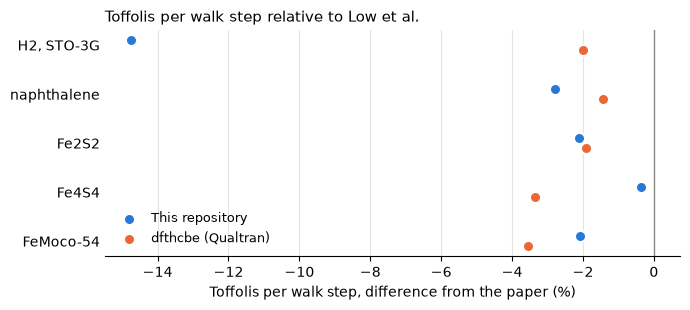

In [6]:
names = [s["label"] for s in systems.values()]
rel = {key: [100 * (s[key] - s["paper"]) / s["paper"] for s in systems.values()]
       for key in ("ours", "dfthcbe")}
y = np.arange(len(names))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvline(0, color="#8a8984", lw=1)
for key, label, color, dy in (("ours", "This repository", "#2a78d6", -0.1),
                              ("dfthcbe", "dfthcbe (Qualtran)", "#eb6834", 0.1)):
    ax.scatter(rel[key], y + dy, s=64, color=color, label=label, zorder=3,
               edgecolor="white", linewidth=1.5)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel("Toffolis per walk step, difference from the paper (%)")
ax.set_title("Toffolis per walk step relative to Low et al.", loc="left", fontsize=11)
ax.grid(axis="x", color="#e4e3df", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.tight_layout()
plt.show()

## 4. Compile and count

Each walk is now compiled to the gate set and counted exactly with `qp.analyze`
(`dfthc.compile.compiled_resources` wraps the qjit/decompose/analyze stack of Section 1). The measured
Toffoli count must equal the closed form of Section 3. By default the small systems compile (H$_2$
and naphthalene, about 10 s each); set `COMPILE_LARGE = True` above for the rest.

In [7]:
def walk_program(s):
    p, t, layout = s["params"], s["tables"], s["layout"]
    def qfunc():
        qp.PhaseGradientStatePrep(layout.phase_grad)
        DFTHCWalk(p.as_compilable(), t.as_compilable(), **layout.groups())
    return qfunc, layout.num_wires

rows = []
for name, s in systems.items():
    if name in LARGE and not COMPILE_LARGE:
        rows.append([s["label"], "—", s["ours"], "skipped", "—", "—", "—"])
        continue
    start = time.perf_counter()
    r = compiled_resources(*walk_program(s))
    seconds = time.perf_counter() - start
    assert r.toffoli == s["ours"], (name, r.toffoli, s["ours"])
    assert r.num_wires == s["layout"].num_wires
    s["compiled"] = r
    rows.append([s["label"], r.toffoli, s["ours"], "equal", r.measured_and_uncomputes,
                 r.measurements, f"{seconds:.0f} s"])

table(["System", "Toffolis compiled", "Closed form", "Check", "Measured AND uncomputes",
       "Mid-circuit measurements", "Compile"], rows)

/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _hadamard_ppm decomposition rule for Hadamard since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _toffoli_elbow decomposition rule for Toffoli since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(
/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cnot_lattice_surgery_ppm decomposition rule for CNOT since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(
/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cz_lattice_surgery_ppm decomposition rule for CZ since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


/Users/isaac/Documents/dfthc-be/.venv/lib/python3.12/site-packages/catalyst/decomposition/decomposition_rules.py:638: RuleLoweringWarning: Excluded the _cphase_to_single_phase decomposition rule for ControlledPhaseShift since --decompose-lowering cannot work with multiple registers yet
  warnings.warn(


| System | Toffolis compiled | Closed form | Check | Measured AND uncomputes | Mid-circuit measurements | Compile |
|---|---|---|---|---|---|---|
| H2, STO-3G | 341 | 341 | equal | 341 | 91 | 11 s |
| naphthalene | 1,910 | 1,910 | equal | 1,910 | 484 | 15 s |
| Fe2S2 | — | 4,411 | skipped | — | — | — |
| Fe4S4 | — | 6,533 | skipped | — | — | — |
| FeMoco-54 | — | 9,790 | skipped | — | — | — |

## 5. FeMoco-54, block by block (the paper's Table III)

Toffolis per walk step for each block of the walk, times the number of calls per step. The paper's
Table III charges the tail-angle fix-up ($N = 54$ Toffolis per call) to the inner unprepare, while
dfthcbe and this repository apply it in the angle erase (step 18); the totals are unaffected.

In [8]:
p = FEMOCO54
paper, ref = costs_reference.paper_table3(p), costs_reference.dfthcbe_blocks(p)
BLOCKS = [  # (row, paper steps, calls per walk, our closed form, reference key)
    ("Outer prepare", "1-4", 1, costs.outer_prepare(p), "outer_prepare"),
    ("Inner prepare", "5-8", 2, costs.inner_prepare(p), "inner_prepare"),
    ("Inner signs", "9", 2, costs.inner_signs(), "inner_signs"),
    ("Tail angle load", "10", 2, costs.tail_angle_load(p), "tail_angle_load"),
    ("SF angle load", "11", 2, costs.sf_angle_load(p), "sf_angle_load"),
    ("Spin multiplexer", "12, 17", 4, costs.spin_mux(), "spin_mux"),
    ("Spin swap", "13, 17", 4, costs.spin_swap(p), "spin_swap"),
    ("Givens ladder", "14", 2, costs.givens_ladder(p), "givens_ladder"),
    ("Majorana gate", "15", 1, costs.majorana_gate(), "majorana_gate"),
    ("Majorana gate (adjoint)", "15", 1, costs.majorana_gate(), "majorana_gate_adjoint"),
    ("Givens ladder (adjoint)", "16", 2, costs.givens_ladder(p), "givens_ladder_dagger"),
    ("Angle erase", "18", 2, costs.angle_erase(p), "angle_erase"),
    ("Inner unprepare", "19-22", 2, costs.inner_unprepare_from_outcomes(p), "inner_unprepare"),
    ("REF_T2", "23", 1, costs.ref_t2(p, False), "ref_t2"),
    ("Outer unprepare", "24-27", 1, costs.outer_unprepare_from_outcomes(p), "outer_unprepare"),
    ("REF_A∪B", "28", 1, costs.ref_ab(p, False), "ref_ab"),
]
rows, totals = [], np.zeros(3, dtype=int)
for label, steps, calls, cost, key in BLOCKS:
    values = np.array([calls * cost.toffoli, calls * ref[key], calls * paper[key]])
    totals += values
    rows.append([label, steps, calls, *map(int, values), f"{int(values[0] - values[2]):+,}"])
rows.append(["**Walk**", "1-28", 1, *[f"**{int(v):,}**" for v in totals],
             f"**{int(totals[0] - totals[2]):+,}**"])
table(["Block", "Steps", "Calls", "Ours", "dfthcbe", "Paper", "Ours − paper"], rows)

# The blocks add up to the walk in all three columns.
assert list(totals) == [costs.walk(p, False).toffoli, ref["walk"], paper["walk"]] == [9790, 9641, 9997]

| Block | Steps | Calls | Ours | dfthcbe | Paper | Ours − paper |
|---|---|---|---|---|---|---|
| Outer prepare | 1-4 | 1 | 209 | 212 | 213 | -4 |
| Inner prepare | 5-8 | 2 | 1,940 | 1,826 | 1,760 | +180 |
| Inner signs | 9 | 2 | 0 | 0 | 0 | +0 |
| Tail angle load | 10 | 2 | 122 | 112 | 108 | +14 |
| SF angle load | 11 | 2 | 582 | 542 | 540 | +42 |
| Spin multiplexer | 12, 17 | 4 | 4 | 8 | 0 | +4 |
| Spin swap | 13, 17 | 4 | 216 | 216 | 216 | +0 |
| Givens ladder | 14 | 2 | 2,968 | 2,968 | 3,180 | -212 |
| Majorana gate | 15 | 1 | 5 | 5 | 7 | -2 |
| Majorana gate (adjoint) | 15 | 1 | 5 | 5 | 7 | -2 |
| Givens ladder (adjoint) | 16 | 2 | 2,968 | 2,968 | 3,180 | -212 |
| Angle erase | 18 | 2 | 204 | 180 | 74 | +130 |
| Inner unprepare | 19-22 | 2 | 434 | 440 | 548 | -114 |
| REF_T2 | 23 | 1 | 20 | 20 | 21 | -1 |
| Outer unprepare | 24-27 | 1 | 69 | 94 | 97 | -28 |
| REF_A∪B | 28 | 1 | 44 | 45 | 46 | -2 |
| **Walk** | 1-28 | 1 | **9,790** | **9,641** | **9,997** | **-207** |

Most of the gap to the paper comes from the Givens ladders: each $R_z$ rotation is an add-or-subtract
into the phase gradient costing $b_\mathrm{rot} - 1$ Toffolis, as in dfthcbe, where the paper counts
$b_\mathrm{rot}$ (`rz-addsub`, −424 per step). Against that, the inner prepares and the angle loads
cost more, mostly because unary iteration here is exact rather than truncated and the inner entry
carries both sign bits; `costs_reference.delta_causes(FEMOCO54)` lists every cause with its
contribution.

## 6. Logical qubits at FeMoco-54

The paper's Table 3 lists 1,131 logical qubits. Here they are grouped by the registers of our
`WalkLayout`.

In [9]:
layout = systems["femoco54"]["layout"]
ours = {name: len(w) for name, w in layout.groups().items()}
theirs = costs_reference.PAPER_QUBIT_GROUPS_FEMOCO
rows = [[f"`{g}`", ours[g], theirs[g], f"{ours[g] - theirs[g]:+,}"] for g in theirs]
rows.append(["**total**", layout.num_wires, costs_reference.PAPER_QUBITS_FEMOCO,
             f"{layout.num_wires - costs_reference.PAPER_QUBITS_FEMOCO:+,}"])
table(["Group", "Ours", "Paper", "Ours − paper"], rows)
assert sum(theirs.values()) == costs_reference.PAPER_QUBITS_FEMOCO == 1131

| Group | Ours | Paper | Ours − paper |
|---|---|---|---|
| `system` | 108 | 108 | +0 |
| `outer` | 71 | 50 | +21 |
| `inner` | 65 | 53 | +12 |
| `select` | 746 | 795 | -49 |
| `phase_grad` | 15 | 15 | +0 |
| `work` | 44 | 110 | -66 |
| **total** | 1,049 | 1,131 | -82 |

The saving is in the `select` and `work` groups: both read registers' junk is measured out right
after each prepare, so it can share the rotation-angle register, and the angle registers drop the
paper's always-zero top bit.

## 7. Phase estimation

Iterative QPE with $t$ bits applies the controlled walk $2^t - 1$ times, plus $(t^3 - t)/6$ Toffolis
of phase corrections in the worst case (`costs.iterative_qpe`). Small cases are compiled in the test
suite (`tests/integration/test_qpe_counts.py`); here are the closed forms at FeMoco-54.

In [10]:
from dfthc.qpe import ControlledWalkPower, spare_wires_needed

p, layout = FEMOCO54, systems["femoco54"]["layout"]
sizes = tuple(len(getattr(layout, g)) for g in ControlledWalkPower.wire_argnames[1:])
rows = []
for t in (1, 2, 3, 10, 20, 23):
    # The walk, a QPE control and t phase-gradient wires; the 2t - 1 correction wires borrow the
    # walk's 44-wire work pool, and only beyond it (t > 22) need spare wires.
    qubits = (WalkLayout.from_params(p, qpe_bits=t).num_wires
              + spare_wires_needed("ControlledWalkPower", sizes, t))
    rows.append([t, costs.iterative_qpe(p, t).toffoli, qubits])
table(["QPE bits t", "Toffolis", "Qubits"], rows)

| QPE bits t | Toffolis | Qubits |
|---|---|---|
| 1 | 9,792 | 1,051 |
| 2 | 29,377 | 1,052 |
| 3 | 68,548 | 1,053 |
| 10 | 10,017,381 | 1,060 |
| 20 | 10,267,647,730 | 1,070 |
| 23 | 82,141,241,768 | 1,074 |

## 8. Correctness: the block encoding of H$_2$

Counting gates is only meaningful if the circuit is right. For H$_2$/STO-3G (4 spin orbitals, at the
test precisions) we decompose `DFTHCBlockEncoding` to the same gate set, run it on the repository's
sparse simulator for each of the 16 system basis states, and project the ancillas onto $|0\rangle$.
The result must equal $\tilde H_{SA}/\tilde\Lambda - I$, the block the classical tables encode
(`dfthc.data.encoded.encoded_block`). Every erase outcome here is forced to 0; the test suite checks
other outcome schedules, the walk's Chebyshev powers and the controlled walk.

In [11]:
from dfthc.ops.walk import DFTHCBlockEncoding
from dfthc.testing import walk_sim

case = walk_sim.case("sto3g")  # H2_STO3G_TEST with the h2_sto3g_R2_B2_C1 factors
ops = walk_sim.program(case, DFTHCBlockEncoding)
outcomes = walk_sim.schedule("S0", walk_sim.num_measurements(ops))

columns = []
for v in range(16):
    state = walk_sim.input_state(case, walk_sim.basis(case, v))
    out = walk_sim.simulate(case, ops, state, outcomes)
    columns.append(walk_sim.project(case, out)[0])
simulated = np.array(columns).T

expected = case.block()
print(f"{len(ops):,} gates, {walk_sim.num_measurements(ops)} mid-circuit measurements")
print(f"max |simulated - expected| = {np.abs(simulated - expected).max():.1e}")
assert np.allclose(simulated, expected, rtol=0, atol=1e-10)

1,318 gates, 48 mid-circuit measurements
max |simulated - expected| = 4.3e-16


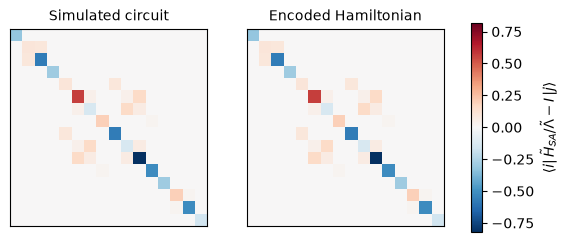

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
for ax, matrix, title in ((axes[0], simulated.real, "Simulated circuit"),
                          (axes[1], expected.real, "Encoded Hamiltonian")):
    lim = np.abs(expected).max()
    im = ax.imshow(matrix, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label=r"$\langle i|\,\tilde H_{SA}/\tilde\Lambda - I\,|j\rangle$")
plt.show()

## 9. How the PennyLane implementation scales

Everything above is a *count*. This section measures what producing the counts costs: compile time
and peak memory as the system grows, how QPE's walk powers compile, and how far the circuits can be
simulated. All timings are on the development laptop (Apple-silicon, 10 cores, 16 GB; PennyLane
0.46.0-dev151, Catalyst 0.16.0-dev140). Each compile runs in its own process under
`dfthc.testing.measure.run_measured`, so the peak memory is that of the whole process, including
about 0.3 GB of imports (JAX, Catalyst, PennyLane) that every compile pays.

### 9.1 The five systems

`docs/resources.json` records every compile of the resource report: the in-process compile time,
the process's wall time and its peak memory. *Compiled gates* counts every operation `qp.analyze`
reports (Cliffords, `TemporaryAND`s, measurements), the size of the circuit as a flat gate list.

In [13]:
report = json.loads((REPO / "docs" / "resources.json").read_text())
compiled = {key: entries[-1] for key, entries in report["compiled"].items()}

def record(system, program):
    r = compiled[f"{system}/{program}"]
    return dict(gates=sum(r["counts"].values()), toffoli=r["toffoli"], wires=r["num_wires"],
                compile_s=r["seconds"], wall_s=r["run"]["seconds"], peak_mb=r["run"]["peak_mb"])

real = {name: record(name, "DFTHCWalk") for name in SYSTEMS}
rows = []
for name, program in [(n, p) for n in SYSTEMS for p in ("DFTHCWalk", "ControlledDFTHCWalk")]:
    r = record(name, program)
    rows.append([SYSTEMS[name][0], program, r["wires"], r["gates"], r["toffoli"],
                 f"{r['compile_s']:.0f} s", f"{r['wall_s']:.0f} s", f"{r['peak_mb'] / 1024:.2f} GB"])
table(["System", "Program", "Qubits", "Compiled gates", "Toffolis", "Compile", "Process wall",
       "Peak memory"], rows)

smallest = min(compiled.values(), key=lambda r: r["run"]["peak_mb"])
print(f"floor: the smallest program in the report ({sum(smallest['counts'].values())} gates) "
      f"takes {smallest['run']['seconds']:.1f} s and {smallest['run']['peak_mb']:.0f} MB")

| System | Program | Qubits | Compiled gates | Toffolis | Compile | Process wall | Peak memory |
|---|---|---|---|---|---|---|---|
| H2, STO-3G | DFTHCWalk | 177 | 4,250 | 341 | 6 s | 7 s | 0.47 GB |
| H2, STO-3G | ControlledDFTHCWalk | 178 | 4,260 | 343 | 8 s | 10 s | 0.62 GB |
| naphthalene | DFTHCWalk | 327 | 64,351 | 1,910 | 10 s | 12 s | 0.60 GB |
| naphthalene | ControlledDFTHCWalk | 328 | 64,361 | 1,912 | 9 s | 11 s | 0.70 GB |
| Fe2S2 | DFTHCWalk | 498 | 436,639 | 4,411 | 15 s | 17 s | 0.77 GB |
| Fe2S2 | ControlledDFTHCWalk | 499 | 436,649 | 4,413 | 17 s | 18 s | 0.90 GB |
| Fe4S4 | DFTHCWalk | 757 | 630,064 | 6,533 | 17 s | 19 s | 0.82 GB |
| Fe4S4 | ControlledDFTHCWalk | 758 | 630,074 | 6,535 | 18 s | 19 s | 0.95 GB |
| FeMoco-54 | DFTHCWalk | 1,049 | 1,495,183 | 9,790 | 32 s | 34 s | 1.24 GB |
| FeMoco-54 | ControlledDFTHCWalk | 1,050 | 1,495,193 | 9,792 | 36 s | 38 s | 1.29 GB |

floor: the smallest program in the report (3 gates) takes 2.1 s and 285 MB


### 9.2 A sweep over system size

The five systems differ in several dimensions at once. For a cleaner curve, `scripts/scaling_sweep.py`
compiles the walk on random factors of FeMoco-54's shape ratios ($B = C = n_+ = N/2$), growing
$N$ from 4 to 54 at $R = 10$ (the last point is FeMoco-54's shape), and $R$ from 2 to 40 at $N = 16$.
Each point reports, besides the process's wall time and peak memory, the time of the classical
tables (`WalkTables.from_factors`) and of the compile, and checks the compiled Toffolis against the
closed form. The recorded run is in `docs/scaling.json`; set `RUN_SCALING_SWEEP = True` to
re-measure it (about 5 minutes, up to 1.3 GB; nothing else heavy should run alongside).

In [14]:
import subprocess

RUN_SCALING_SWEEP = False  # True re-measures docs/scaling.json (about 5 min, up to 1.3 GB)
if RUN_SCALING_SWEEP:
    subprocess.run([sys.executable, str(REPO / "scripts" / "scaling_sweep.py")], cwd=REPO,
                   env={**__import__("os").environ, "PYTHONPATH": str(REPO / "src")}, check=True)
sweep = json.loads((REPO / "docs" / "scaling.json").read_text())
points = sweep["points"]
n_sweep = sorted((p for p in points if p["sweep"] == "N"), key=lambda p: p["N"])
r_sweep = sorted((p for p in points if p["N"] == 16), key=lambda p: p["R"])

table(["N", "R", "Qubits", "Toffolis", "Compiled gates", "Tables", "Compile (wall)",
       "Compile (CPU)", "Process wall", "Peak memory"],
      [[p["N"], p["R"], p["wires"], p["toffoli"], p["gates"], f"{p['tables_s']:.2f} s",
        f"{p['compile_s']:.1f} s", f"{p['compile_cpu_s']:.1f} s", f"{p['wall_s']:.1f} s",
        f"{p['peak_mb']:.0f} MB"] for p in n_sweep + [p for p in r_sweep if p["R"] != 10]])

| N | R | Qubits | Toffolis | Compiled gates | Tables | Compile (wall) | Compile (CPU) | Process wall | Peak memory |
|---|---|---|---|---|---|---|---|---|---|
| 4 | 10 | 222 | 863 | 18,007 | 0.01 s | 13.0 s | 11.9 s | 18.5 s | 523 MB |
| 8 | 10 | 293 | 1,649 | 57,588 | 0.01 s | 24.0 s | 21.5 s | 30.8 s | 586 MB |
| 12 | 10 | 362 | 2,320 | 93,048 | 0.02 s | 22.7 s | 21.0 s | 29.5 s | 605 MB |
| 16 | 10 | 428 | 3,193 | 203,499 | 0.02 s | 25.9 s | 24.1 s | 32.5 s | 693 MB |
| 24 | 10 | 561 | 4,498 | 334,849 | 0.02 s | 24.5 s | 23.5 s | 28.9 s | 721 MB |
| 32 | 10 | 691 | 6,273 | 772,304 | 0.03 s | 43.1 s | 41.2 s | 46.7 s | 986 MB |
| 40 | 10 | 821 | 7,566 | 1,016,141 | 0.05 s | 56.2 s | 53.1 s | 60.0 s | 935 MB |
| 48 | 10 | 952 | 8,821 | 1,281,945 | 0.06 s | 57.7 s | 55.6 s | 62.1 s | 1051 MB |
| 54 | 10 | 1,049 | 9,790 | 1,495,183 | 0.08 s | 57.9 s | 56.0 s | 62.6 s | 1164 MB |
| 16 | 2 | 418 | 2,442 | 61,883 | 0.01 s | 10.3 s | 9.9 s | 13.8 s | 606 MB |
| 16 | 5 | 425 | 2,823 | 113,983 | 0.01 s | 11.8 s | 11.4 s | 15.2 s | 655 MB |
| 16 | 20 | 434 | 3,858 | 383,029 | 0.01 s | 21.3 s | 20.7 s | 25.2 s | 773 MB |
| 16 | 40 | 634 | 4,853 | 755,556 | 0.03 s | 34.6 s | 33.9 s | 38.7 s | 1002 MB |

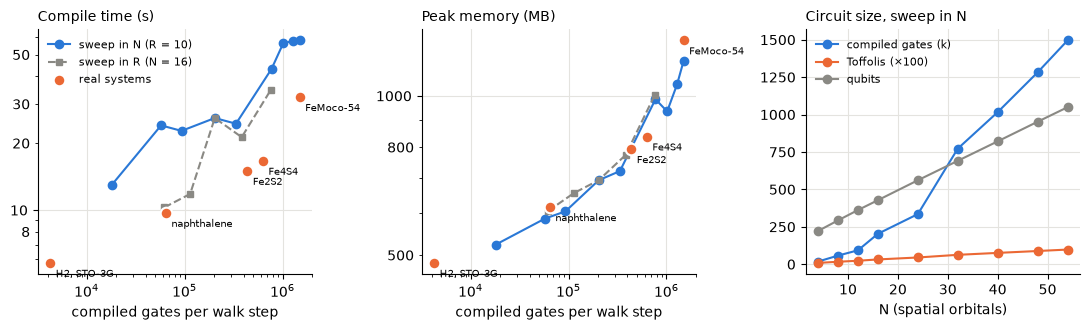

N >= 16: compile time ~ gates^0.49, peak memory above the 0.3 GB floor ~ gates^0.39
N = 4 to 54: gates x83, Toffolis x11.3, compile time x4.5, peak memory x2.2
compiled gates per second at N = 54: 25,824


In [15]:
def slope(xs, ys):
    # Least-squares exponent of y ~ x^k on a log-log scale.
    return np.polyfit(np.log(xs), np.log(ys), 1)[0]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
quantities = (("compile_s", "Compile time (s)"), ("peak_mb", "Peak memory (MB)"))
for ax, (key, label) in zip(axes[:2], quantities):
    ax.plot([p["gates"] for p in n_sweep], [p[key] for p in n_sweep], "o-", color="#2a78d6",
            label="sweep in N (R = 10)")
    ax.plot([p["gates"] for p in r_sweep], [p[key] for p in r_sweep], "s--", color="#8a8984",
            label="sweep in R (N = 16)", ms=5)
    ax.scatter([r["gates"] for r in real.values()], [r[key] for r in real.values()], s=70,
               color="#eb6834", zorder=3, edgecolor="white", linewidth=1.5, label="real systems")
    for name, r in real.items():
        ax.annotate(SYSTEMS[name][0], (r["gates"], r[key]), fontsize=7,
                    xytext=(4, -10), textcoords="offset points")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if str(v)[0] in "2358" else ""))
    ax.set_xlabel("compiled gates per walk step"); ax.set_title(label, loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)

ax = axes[2]
ns = [p["N"] for p in n_sweep]
ax.plot(ns, [p["gates"] / 1e3 for p in n_sweep], "o-", color="#2a78d6", label="compiled gates (k)")
ax.plot(ns, [p["toffoli"] / 1e2 for p in n_sweep], "o-", color="#eb6834", label="Toffolis (×100)")
ax.plot(ns, [p["wires"] for p in n_sweep], "o-", color="#8a8984", label="qubits")
ax.set_xlabel("N (spatial orbitals)"); ax.set_title("Circuit size, sweep in N", loc="left",
                                                      fontsize=10)
ax.legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(color="#e4e3df", lw=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

big = [p for p in n_sweep if p["N"] >= 16]
gates, comp, mem = ([p[k] for p in big] for k in ("gates", "compile_s", "peak_mb"))
print(f"N >= 16: compile time ~ gates^{slope(gates, comp):.2f}, "
      f"peak memory above the 0.3 GB floor ~ gates^{slope(gates, [m - 300 for m in mem]):.2f}")
print(f"N = 4 to 54: gates x{n_sweep[-1]['gates'] / n_sweep[0]['gates']:.0f}, "
      f"Toffolis x{n_sweep[-1]['toffoli'] / n_sweep[0]['toffoli']:.1f}, "
      f"compile time x{n_sweep[-1]['compile_s'] / n_sweep[0]['compile_s']:.1f}, "
      f"peak memory x{n_sweep[-1]['peak_mb'] / n_sweep[0]['peak_mb']:.1f}")
print(f"compiled gates per second at N = 54: {n_sweep[-1]['gates'] / n_sweep[-1]['compile_s']:,.0f}")

### 9.3 Phase estimation: walk powers do not unroll

`ControlledWalkPower` repeats the controlled walk in a `qp.for_loop` with a static bound, and
`qp.analyze` multiplies the body's counts by the trip count. The loop body is compiled once, so a
walk power costs the same to compile whatever its exponent: in the report, doubling the power
doubles the gates and leaves the compile time and memory unchanged.

In [16]:
rows = []
for name in SYSTEMS:
    if f"{name}/ControlledWalkPower(p=2)" not in compiled:
        continue
    for power in (1, 2):
        r = record(name, f"ControlledWalkPower(p={power})")
        rows.append([SYSTEMS[name][0], power, r["gates"], r["toffoli"], f"{r['compile_s']:.1f} s",
                     f"{r['peak_mb']:.0f} MB"])
table(["System", "Power p", "Compiled gates", "Toffolis", "Compile", "Peak memory"], rows)

| System | Power p | Compiled gates | Toffolis | Compile | Peak memory |
|---|---|---|---|---|---|
| H2, STO-3G | 1 | 4,260 | 343 | 8.1 s | 629 MB |
| H2, STO-3G | 2 | 8,519 | 686 | 8.2 s | 691 MB |
| naphthalene | 1 | 64,361 | 1,912 | 9.6 s | 763 MB |
| naphthalene | 2 | 128,721 | 3,824 | 9.7 s | 761 MB |
| Fe2S2 | 1 | 436,649 | 4,413 | 16.7 s | 965 MB |
| Fe2S2 | 2 | 873,297 | 8,826 | 17.0 s | 962 MB |
| Fe4S4 | 1 | 630,074 | 6,535 | 18.3 s | 986 MB |
| Fe4S4 | 2 | 1,260,147 | 13,070 | 18.2 s | 1043 MB |

A $t$-bit iterative QPE is $t$ rounds with powers $2^0, \dots, 2^{t-1}$, so its compile grows with
$t$ (one loop body per round), not with the $2^t - 1$ walk steps it applies. FeMoco-54's $t = 23$
estimate (about $8.2 \times 10^{10}$ Toffolis) would therefore be a few dozen loop bodies rather than
$8 \times 10^6$ copies of the walk. Section 7's numbers are closed forms; only the walk and the
controlled walk are compiled at FeMoco-54.

### 9.4 Simulation runtime

The circuits are far too wide for a state-vector simulator (177 to 1,049 qubits at the paper's
precisions). Correctness is instead checked on the repository's sparse simulator
(`dfthc.testing.sparse_sim`), which stores only the nonzero amplitudes. Its cost follows the number
of nonzero terms, i.e. the product of the superpositions alive at once (the phase-gradient state,
the prepared index registers, the system state), not the qubit count. Below: one walk step on one
basis state of H$_2$ at the test precisions, gate by gate.

In [17]:
from dfthc.testing.sparse_sim import ForcedPolicy, SparseSimulator

SIMULATE_631G = False  # True also simulates H2/6-31G (about 1 minute)

def simulate_walk(case_name):
    case = walk_sim.case(case_name)
    start = time.perf_counter()
    ops = walk_sim.program(case, DFTHCWalk)  # decomposed in tape mode, no Catalyst
    built = time.perf_counter()
    sim = SparseSimulator(case.num_wires, strict=True,
                          policy=ForcedPolicy(walk_sim.schedule("S0", walk_sim.num_measurements(ops))))
    final = sim.run(ops, walk_sim.input_state(case, walk_sim.basis(case, 1)))
    done = time.perf_counter()
    return [case_name, case.num_wires, len(ops), f"{built - start:.1f} s", f"{done - built:.1f} s",
            f"{len(final.amps):,}"]

table(["Case", "Qubits", "Gates", "Decompose", "Simulate", "Nonzero terms at the end"],
      [simulate_walk(c) for c in ("sto3g", *(["631g"] if SIMULATE_631G else []))])

| Case | Qubits | Gates | Decompose | Simulate | Nonzero terms at the end |
|---|---|---|---|---|---|
| sto3g | 56 | 1,358 | 0.7 s | 1.0 s | 16,512 |

### 9.5 What the measurements say

- **The circuit grows faster than the compile.** Along the FeMoco-shaped sweep, Toffolis grow
  about linearly in $N$ ($\sim N^{0.94}$) and qubits as $\sim N^{0.6}$. The full gate count grows
  as $\sim N^{1.75}$, because it is dominated by Cliffords. At FeMoco-54, 66% of the gates are
  CNOTs and 31% are Pauli-Xs, most of them from the QROM data loads and angle loads, whose tables
  grow faster than the Toffoli count. Compile time grows only as about (gates)$^{0.5}$, and peak memory above the
  import floor as about (gates)$^{0.4}$. From $N = 4$ to FeMoco-54's shape, the circuit grows by a
  factor of 83 while compile time grows by 4.5 and memory by 2.2. The 1.5 million gates of a
  FeMoco-54 walk step compile in 0.5–1 minute and 1.2–1.3 GB on a laptop.
- **Why it is sublinear: the flat circuit is never built.** Under `qp.qjit(capture=True)` the
  program stays structured. Each operator is decomposed by one pinned rule, which is traced once
  per distinct set of compile-time arguments. The data loads and walk powers are `qp.for_loop`s.
  `qp.analyze` then counts the structured program, multiplying loop bodies by their static trip
  counts, instead of enumerating 1.5 M gates. The cost tracks the number of distinct rule
  instances and the size of the classical tables (each distinct table is its own rule compile,
  catalyst#3173 / L-21), not the length of the gate list.
- **A fixed cost dominates small systems.** Every compile pays about 0.3 GB and 2–5 s for the
  imports, and roughly 5–10 s to solve the decomposition graph and run the MLIR pipeline. An H$_2$
  walk with 4,000 gates compiles in 6 s, and a naphthalene walk with 16 times as many gates in 10 s.
- **Classical preprocessing is negligible.** Building the alias, angle and QROM tables
  (`WalkTables.from_factors`) takes under 0.05 s even at FeMoco-54's shape.
- **QPE compiles with $t$, not $2^t$.** A walk power is a loop, so its compile cost does not
  depend on its exponent (Section 9.3).
- **Simulation, not compilation, is the wall.** The sparse simulator's cost follows the number of
  nonzero amplitudes, which is exponential in the widths of the registers held in superposition.
  At the reduced test precisions, one H$_2$/STO-3G walk step takes about 1 s; H$_2$/6-31G holds
  about 210,000 terms at its peak and takes about 1 minute. Nothing larger can be simulated, so
  correctness beyond H$_2$ rests on the per-block tests and on every compiled count matching its
  closed form.
- **Caveat on the timings.** Both `docs/scaling.json` and `docs/resources.json` were measured on a
  laptop that was in use. Wall times vary by up to about 2× between runs: the FeMoco-54 walk
  compiled in 32 s for the report and in 58 s in the sweep, with identical counts. The exponents and
  ratios are more reliable than any single time.

## 10. Changes needed in PennyLane

This repository works around a set of PennyLane and Catalyst behaviours; each is pinned by a canary
test and described in `docs/limitations.md` (L-numbers below). The list below covers the
**PennyLane repository** (`PennyLaneAI/pennylane`, main branch): first the fixes that would let
the workarounds go, then the building blocks that would make a DFTHC walk native to PennyLane. The
behaviour was observed on 0.46.0-dev151; issue states were checked on GitHub on 2026-11-20.
**Scaling** marks items that change the compile cost measured in Section 9.

### Bugs and behaviour to fix

| # | Change | Why it matters here | Upstream |
|---|---|---|---|
| 1 | **Scaling.** Rewrite `FlipSign`'s decomposition so that compile time does not grow exponentially with the pattern width. It declares its multi-controlled `Z` with traced control values. Also give `qp.ctrl(GlobalPhase)` a Toffoli-level path. | The walk's reflections need 20–46 pattern wires. `FlipSign` takes 20 s at 6 wires and more than 6 min and 2.8 GB at 14 (L-29). `QubitizationTHC` in PennyLane uses `FlipSign` for its reflection too. | no issue filed |
| 2 | **Scaling.** Under control, use a pinned measuring `Adjoint(Op)` rule or raise an error. Today the solver silently controls the unitary inverse instead. | The result has wrong Toffoli and measurement counts, with no error. The generic controlled candidate also adds 26% compile memory at naphthalene (L-2). | #9629 merged; the silent fallback remains |
| 3 | `C(ChangeOpBasis)` should control only the middle operator under capture. | It costs two Toffolis instead of zero. This forces a hand-written `C(DFTHCWalk)` rule (L-7). | #10357 open |
| 4 | Generic controlled decomposition should not add a `PauliX` pair per control wire. | Counts are inflated (L-8). | #10080 open |
| 5 | Pause capture while resource functions run. | Every resource key needs a `qp.capture.pause()` wrapper (L-11). | #10162 open |
| 6 | Canonicalize list-valued dynamic arguments of `Operator2` to arrays. | Each operator converts them by hand (L-23). | #10060 open |
| 7 | Make `fixed_decomps` pins apply per operator instance, or provide a non-recursive pin. | Pinning `QROM` to select-swap leaves its nested `QROM` with no path (L-4, L-12). | no issue filed |
| 8 | Make the select-swap `QROM` resource function return concrete (non-symbolic) counts. | Because of it, `QROAMRead` pins `QROM` to unary iteration and builds its own CSWAP network (L-12, L-22). | no issue filed |
| 9 | Give `Toffoli` and `CSWAP` a rule that takes a caller-supplied zeroed wire. Their elbow rule allocates, and Catalyst now skips allocating rules. | Every Toffoli in the walk is a hand-built two-control `MultiControlledX` with an explicit work wire (L-1). | catalyst#3243 merged (the skip); no PennyLane-side rule |
| 10 | Give `MultiControlledX` a path without work wires (for example, a relative-phase ladder). | Without one, every reflection must be lent work wires (L-14). | no issue filed |
| 11 | Give `UniformPrep` and `AliasSampling` a Clifford+Toffoli path for sizes that are not a power of two (a flagged uniform preparation with a comparator). | Neither compiles to the gate set at L = 5 (L-19). This repository has its own `FlaggedUniformPrep`. | no issue filed |
| 12 | Let `QROM` take `MeasurementValue`s as data in tape mode. | It would remove one Toffoli per erase fix-up, three per FeMoco-54 walk, and keep tape-mode simulation working (L-28). | no issue filed |
| 13 | Support `hw-like` postselection under capture: at present it raises `CompileError`. | It is unusable with `qjit(capture=True)` (L-15). | #8379 open |

### Building blocks to add (to sit beside the THC templates in `templates/subroutines/`)

PennyLane already ships `QubitizationTHC`, `SelectTHC`, `AliasSamplingTHC`, `PhaseGradientStatePrep`,
`TemporaryAND` and phase-gradient decompositions of `RZ` and `SelectPauliRot`. To compile the DFTHC
walk from PennyLane alone it would also need these, each with an exact resource function:

1. **A unary-iteration primitive**: address ranges with a lower bound, nested ranges, an enable on
   value 1, and leaves that apply phases. `QROM` covers only the full range $[0, 2^n)$ with `MultiX`
   leaves, and `Select` over shared targets crashes the compiler (L-13). The repository's
   `dfthc.ops.unary` is the template for this.
2. **A QROAM read with measured erase**: a dirty select-swap read whose junk is X-measured and whose
   phase is fixed up from measurement parities (`QROAMRead`, `QROAMErase`, `PhaseFixup`), with
   exact, non-symbolic counts. The prepares and the angle loads are built on it.
3. **Measurement-parity predicates under capture**: a helper that conditions on the parity of many
   mid-circuit measurement outcomes. Capture mode would compute it as a packed popcount, and tape
   mode as one flat `MeasurementValue` (`dfthc.compile.mcm_parities`).
4. **A Toffoli-level flagged uniform preparation** (item 11 above, as a template).
5. **A rotation by addition into the phase gradient** with a classical or quantum angle register
   (`PhaseGradientRotation`, the Givens ladders). This costs $b_\mathrm{rot} - 1$ Toffolis per
   rotation, with an angle loaded from QROM rather than a fixed `RZ` angle.
6. **A pinned `C(Qubitization)`-style rule that controls only the reflections**, so that a
   controlled walk costs about 2 Toffolis more than the walk instead of controlling every gate
   (items 3 and 4 above).
7. **Iterative QPE as a template** with walk powers as static `for_loop`s and measured phase
   corrections, whose resources come from a single loop body. `qp.iterative_qpe` exists, but it is
   not a decomposable `Operator2` with a resource function.
8. **The DFTHC-specific blocks**: the spin multiplexer and spin swap, the Majorana gate, the Givens
   ladder and its adjoint, and the outer and inner prepare/unprepare. These are the
   `dfthc.ops` operators, with the closed forms of `dfthc.costs` as their resource functions.

### Catalyst changes (not PennyLane, but they set the compile cost)

- **Scaling, catalyst#3173 (open)**: decomposition rules are recompiled for every distinct table. In
  this program, compile time therefore grows with the size of the classical data rather than with
  the number of distinct operators. One 8,640-entry table takes 23 s and 0.9 GB (L-21). This is
  the main lever on the compile times in Section 9.
- **Scaling, L-27**: `qp.qjit` compiles a fully annotated (or zero-argument) function at decoration,
  so `qp.analyze` compiles it a second time. Switching this off reduced one controlled walk from
  73 s and 2.6 GB to 26 s and 1.5 GB.
- catalyst#3172 (rules cannot specialize on constant parameters), catalyst#3217 (adjoint-lowering
  crash), catalyst#3384 (function calls in control regions), catalyst#3431 (order-dependent rule
  lowering) and catalyst#2767 (unclear "rules file could not be parsed" error) are all open.
- Unsigned dynamic arguments get no rule (L-26). Integers wider than 64 bits are rejected (L-24).
  `Select` with shared target wires crashes (L-13). `pauli_measure` postselection is ignored
  (catalyst#3338). Measurements inside `qp.cond` under one-shot execution are mishandled
  (catalyst#2382).

## Summary

| | Paper | This repository | dfthcbe |
| --- | ---: | ---: | ---: |
| Toffolis per walk step, FeMoco-54 | 9,997 | 9,790 (controlled: 9,792) | 9,641 |
| Logical qubits, FeMoco-54 | 1,131 | 1,049 | — |
| Compile of one FeMoco-54 walk step (1.5 M gates) | — | 0.5–1 min, 1.2–1.3 GB | — |

Every count above comes from a circuit that compiles to Cliffords, `TemporaryAND` and measurements,
and every compiled count equals its closed form. For the full per-block report of every system,
with Cliffords, measurements and the cause of each difference, see `docs/resources.md`
(regenerated by `scripts/resource_report.py`).